# Evaluating Inter-annotator agreement

This notebook aims to evaluate the inter-annotator agreement using Cohen's Kappa statistic. 

Cohen's Kappa measures the level of agreement between the evaluations of 2 annotators and requires that both annotators evaluate the same data points. It can not be applied to scenarios[1] with more than 2 annotators, and all data points must have been evaluated (that means, any null evaluation should be removed from the analysis). 

This statistic varies from -1 to 1, being 0.8 to 1 values considered as a high level of agreement and values between -1 and 0 considered as no agreement.

[1] For those scenarios, there are other statistics to be considered, such as Kleiss' Kappa or Kripendorff's Alpha. 

## Dataset

I found the HelpSteer3 dataset, developed by Nvidia and published on Hugging Face. The dataset is designed to evaluate the performance of large language models in generating helpful responses to user queries. Hugging Face mentions each data point was evaluated by three annotators for individual preference. 

The dataset is available at: https://huggingface.co/datasets/nvidia/Multilingual-Individual-Preference and the required citations are as follows:

@misc{wang2023helpsteer,
      title={HelpSteer: Multi-attribute Helpfulness Dataset for SteerLM}, 
      author={Zhilin Wang and Yi Dong and Jiaqi Zeng and Virginia Adams and Makesh Narsimhan Sreedhar and Daniel Egert and Olivier Delalleau and Jane Polak Scowcroft and Neel Kant and Aidan Swope and Oleksii Kuchaiev},
      year={2023},
      eprint={2311.09528},
      archivePrefix={arXiv},
      primaryClass={cs.CL}
}

@misc{dong2023steerlm,
      title={SteerLM: Attribute Conditioned SFT as an (User-Steerable) Alternative to RLHF}, 
      author={Yi Dong and Zhilin Wang and Makesh Narsimhan Sreedhar and Xianchao Wu and Oleksii Kuchaiev},
      year={2023},
      eprint={2310.05344},
      archivePrefix={arXiv},
      primaryClass={cs.CL}
}

In [1]:
import pandas as pd
from datasets import load_dataset
ds = load_dataset("nvidia/HelpSteer3") # returns a DatasetDict with train, validation, and test splits
print(ds)                          # shows splits and column names

df = ds["train"].to_pandas()
df.head()

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['domain', 'language', 'context', 'response1', 'response2', 'overall_preference', 'individual_preference'],
        num_rows: 38459
    })
    validation: Dataset({
        features: ['domain', 'language', 'context', 'response1', 'response2', 'overall_preference', 'individual_preference'],
        num_rows: 2017
    })
})


,domain,language,context,response1,response2,overall_preference,individual_preference
0,code,python,"[{'role': 'user', 'content': 'lets do python c...","Yes, you are correct. The correct comparison o...",Sure! Here's the updated line of code with `<`...,-2,"[{'score': -2, 'reasoning': '@Response 1 is be..."
1,code,python,"[{'role': 'user', 'content': '1. Hello :) Toda...","Y, I understand how Midjourney works based on ...",READ,-3,"[{'score': -3, 'reasoning': '@Response 1 is mu..."
2,code,javascript_html_css,"[{'role': 'user', 'content': 'Hello. I am a Fa...",I'm glad to hear that you understand the impo...,"I understand, and I apologize if my response c...",1,"[{'score': 1, 'reasoning': '@Response 2 is sli..."
3,code,go,"[{'role': 'user', 'content': 'We have an objec...","To achieve this in Go, you can use the `githu...","To achieve this, you can use the `HSETNX` comm...",-1,"[{'score': -1, 'reasoning': '@Response 1 is sl..."
4,code,python,"[{'role': 'user', 'content': 'generate apache ...",```python\nfrom flask import Flask\nfrom flask...,To add database migration support using Flask-...,-1,"[{'score': -1, 'reasoning': '@Response 1 is sl..."


Let's explore its distribution:

In [2]:
df.shape # number of rows in the dataset
print(f"Rows: {df.shape[0]} rows")
print(f"Columns: {df.shape[1]} columns")
print(f"Column names: {df.columns.tolist()}")

Rows: 38459 rows
Columns: 7 columns
Column names: ['domain', 'language', 'context', 'response1', 'response2', 'overall_preference', 'individual_preference']


In [3]:
df["domain"].value_counts() # distribution of the domain column

domain
general         17707
code             8419
multilingual     7660
stem             4673
Name: count, dtype: int64

It contains the following domains: general, code, multilingual, and stem.
I am interested in the multilingual subset of the data, so I'll focus on it. 

In [4]:
df_multilingual = df[df['domain'] == 'multilingual']
print(f"Rows: {df_multilingual.shape[0]} rows")
print(f"Columns: {df_multilingual.shape[1]} columns")
df_multilingual['language'].value_counts() # distribution of the language column

Rows: 7660 rows
Columns: 7 columns


language
chinese       2306
french         790
korean         790
spanish        778
japanese       534
german         462
russian        458
portuguese     437
italian        407
dutch          185
vietnamese     184
polish         173
indonesian     156
Name: count, dtype: int64

As seen above, the multilingual dataset contains 7,660 samples in 13 languages. The individual preference per annotator is in the 'individual_preference' column.

In [5]:
print(type(df_multilingual['individual_preference']))

<class 'pandas.Series'>


In [6]:
df_multilingual["scores"] = df_multilingual["individual_preference"].apply(lambda anns: [a["score"] for a in anns])
print(df_multilingual["scores"].head())

30799       [1, 2, 2]
30800             [3]
30801    [-3, -1, -1]
30802      [1, -1, 1]
30803    [-3, -3, -3]
Name: scores, dtype: object


Given that the "individual_preference" column contains a dictionary with an array of dictionaries, we can extract the "score" values from each inner dictionary and create a new dataframe "raters" with 3 columns called rater_1, rater_2, and rater_3. This will allow us to analyze the scores more easily.

In [7]:
raters = pd.DataFrame(df_multilingual["scores"].tolist(), index=df_multilingual.index)
raters.columns = [f"rater_{i+1}" for i in raters.columns]

raters['rater_2'] = raters['rater_2'].astype('Int64')  # Convert rater_2 to nullable integer type
raters['rater_3'] = raters['rater_3'].astype('Int64')
print(raters)

       rater_1  rater_2  rater_3
30799        1        2        2
30800        3     <NA>     <NA>
30801       -3       -1       -1
30802        1       -1        1
30803       -3       -3       -3
...        ...      ...      ...
38454       -2       -3       -1
38455        3        3        2
38456       -1       -2       -1
38457        1       -1       -1
38458        2        1        2

[7660 rows x 3 columns]


In [8]:
df_multilingual = df_multilingual.join(raters)
df_multilingual.head()

,domain,language,context,response1,response2,overall_preference,individual_preference,scores,rater_1,rater_2,rater_3
30799,multilingual,chinese,"[{'role': 'user', 'content': '你是花蓮縣國中老師，要教國中七年...","Sure, I can help you create a concept map for...",Title: 服飾和傳統建築的文化課程\n\n第一層：主題與目標\n\n1. 介紹布農族、阿...,2,"[{'score': 1, 'reasoning': '@Response 2 is sli...","[1, 2, 2]",1,2,2
30800,multilingual,portuguese,"[{'role': 'user', 'content': 'hashtags para co...","Claro, aqui estão algumas hashtags populares e...","Sim, você pode usar hashtags em maiúsculas ou ...",3,"[{'score': 3, 'reasoning': '@Response 2 is muc...",[3],3,<NA>,<NA>
30801,multilingual,russian,"[{'role': 'user', 'content': 'как профессионал...","As a professional translator, I would translat...",You are a professional social media marketing ...,-2,"[{'score': -3, 'reasoning': '@Response 1 is mu...","[-3, -1, -1]",-3,-1,-1
30802,multilingual,french,"[{'role': 'user', 'content': 'I run a professi...","Bien sûr, je serais heureux de vous aider à cr...","Bien sûr, voici une liste de titres de blogs e...",0,"[{'score': 1, 'reasoning': '@Response 2 is sli...","[1, -1, 1]",1,-1,1
30803,multilingual,chinese,"[{'role': 'user', 'content': '我們來角色扮演，我演熙貴妃，你演...",臣妾斕常在，拜見熙貴妃。臣妾深知此事事关重大，必须严肃处理。臣妾愿意接受任何处罚，以维护皇...,皇上，我深知皇上对皇室继承的期望和愿望。我将继续致力于我的职责，以便为皇上的皇室服务。如果您...,-3,"[{'score': -3, 'reasoning': '@Response 1 is mu...","[-3, -3, -3]",-3,-3,-3


## Prepare dataset for Cohen's Kappa analyis

We notice that all rows have been evaluated by all of the annotatores. Also, there is not annotator id, so a mix of annotators could have evaluated the rows.
To evaluate the inter-annotator agreement with the Cohen's Kappa statistic:
- Let's assume that all rows corresponding to a language were evaluated by the same 2 annotators.
- Let's only focus on rater_1 and rater_2 evaluations for rows with no null values.

In [9]:
df_cohen = df_multilingual.drop(columns=["scores","rater_3"])
df_cohen.head()

,domain,language,context,response1,response2,overall_preference,individual_preference,rater_1,rater_2
30799,multilingual,chinese,"[{'role': 'user', 'content': '你是花蓮縣國中老師，要教國中七年...","Sure, I can help you create a concept map for...",Title: 服飾和傳統建築的文化課程\n\n第一層：主題與目標\n\n1. 介紹布農族、阿...,2,"[{'score': 1, 'reasoning': '@Response 2 is sli...",1,2
30800,multilingual,portuguese,"[{'role': 'user', 'content': 'hashtags para co...","Claro, aqui estão algumas hashtags populares e...","Sim, você pode usar hashtags em maiúsculas ou ...",3,"[{'score': 3, 'reasoning': '@Response 2 is muc...",3,<NA>
30801,multilingual,russian,"[{'role': 'user', 'content': 'как профессионал...","As a professional translator, I would translat...",You are a professional social media marketing ...,-2,"[{'score': -3, 'reasoning': '@Response 1 is mu...",-3,-1
30802,multilingual,french,"[{'role': 'user', 'content': 'I run a professi...","Bien sûr, je serais heureux de vous aider à cr...","Bien sûr, voici une liste de titres de blogs e...",0,"[{'score': 1, 'reasoning': '@Response 2 is sli...",1,-1
30803,multilingual,chinese,"[{'role': 'user', 'content': '我們來角色扮演，我演熙貴妃，你演...",臣妾斕常在，拜見熙貴妃。臣妾深知此事事关重大，必须严肃处理。臣妾愿意接受任何处罚，以维护皇...,皇上，我深知皇上对皇室继承的期望和愿望。我将继续致力于我的职责，以便为皇上的皇室服务。如果您...,-3,"[{'score': -3, 'reasoning': '@Response 1 is mu...",-3,-3


In [10]:
print(f"Null values in rater_1: {df_cohen['rater_1'].isna().sum()}")
print(f"Null values in rater_2: {df_cohen['rater_2'].isna().sum()}")

Null values in rater_1: 0
Null values in rater_2: 184


In [11]:
df_cohen = df_cohen.dropna(subset=["rater_2"])

New number of rows after dropping null values in rater_2:

In [12]:
print(f"Rows after dropping null values in rater_2: {df_cohen.shape[0]} rows")

Rows after dropping null values in rater_2: 7476 rows


In [13]:
df_cohen.head()

,domain,language,context,response1,response2,overall_preference,individual_preference,rater_1,rater_2
30799,multilingual,chinese,"[{'role': 'user', 'content': '你是花蓮縣國中老師，要教國中七年...","Sure, I can help you create a concept map for...",Title: 服飾和傳統建築的文化課程\n\n第一層：主題與目標\n\n1. 介紹布農族、阿...,2,"[{'score': 1, 'reasoning': '@Response 2 is sli...",1,2
30801,multilingual,russian,"[{'role': 'user', 'content': 'как профессионал...","As a professional translator, I would translat...",You are a professional social media marketing ...,-2,"[{'score': -3, 'reasoning': '@Response 1 is mu...",-3,-1
30802,multilingual,french,"[{'role': 'user', 'content': 'I run a professi...","Bien sûr, je serais heureux de vous aider à cr...","Bien sûr, voici une liste de titres de blogs e...",0,"[{'score': 1, 'reasoning': '@Response 2 is sli...",1,-1
30803,multilingual,chinese,"[{'role': 'user', 'content': '我們來角色扮演，我演熙貴妃，你演...",臣妾斕常在，拜見熙貴妃。臣妾深知此事事关重大，必须严肃处理。臣妾愿意接受任何处罚，以维护皇...,皇上，我深知皇上对皇室继承的期望和愿望。我将继续致力于我的职责，以便为皇上的皇室服务。如果您...,-3,"[{'score': -3, 'reasoning': '@Response 1 is mu...",-3,-3
30804,multilingual,italian,"[{'role': 'user', 'content': 'come spiego il c...",Una organizzazione meccanica è una organizzazi...,Le organizzazioni meccaniche e innovative sono...,1,"[{'score': 1, 'reasoning': '@Response 2 is sli...",1,1


In [14]:
# Exporting the dataframe to a CSV file for future uses
df_cohen.to_csv("df_cohen.csv")

## Running cohen_kappa_score per language

Given that rater_1 and rater_2 contain preference ratings on a 7-point ordinal scale from -3 to +3, and not just a binary label (e.g.: 0 and 1), let's use a weighted Cohen's Kappa score. 

In [ ]:
from sklearn.metrics import cohen_kappa_score

In [ ]:
cohen_per_language = pd.DataFrame() 
# Creating a dataset with each language to get Cohen's Kappa calculation for each language
for language in df_cohen['language'].unique():
    df_language = df_cohen[df_cohen['language'] == language]
    linear_kappa = cohen_kappa_score(df_language['rater_1'], df_language['rater_2'], weights='linear')
    quadratic_kappa = cohen_kappa_score(df_language['rater_1'], df_language['rater_2'], weights='quadratic')
    cohen_per_language = pd.concat([cohen_per_language, pd.DataFrame({'language': [language], 'linear_kappa': [linear_kappa], 'quadratic_kappa': [quadratic_kappa]})], ignore_index=True)

In [94]:
print(cohen_per_language.sort_values(by='quadratic_kappa', ascending=False))

      language  linear_kappa  quadratic_kappa
0      chinese      0.678723         0.843464
10      korean      0.653783         0.834331
6   portuguese      0.658981         0.823212
12       dutch      0.633016         0.823053
11      polish      0.632334         0.819491
8     japanese      0.644377         0.816010
4   vietnamese      0.635162         0.815927
9   indonesian      0.603564         0.799283
1      russian      0.598015         0.792675
3      italian      0.587043         0.789279
5      spanish      0.599466         0.778687
2       french      0.593729         0.773049
7       german      0.546375         0.745181


The quadratic weighted Cohen's Kappa is usually higher than the linear weighted option. The quadratic version penalizes bigger differences between scores more than smaller differences. 
The quadratic weighted Kappa ranges from 0.75 to 0.84. According to Landis & Koch rule of thumb, a Kappa between 0.61 and 0.8 shows a substantial agreement, while values above 0.8 and 1 show an almost perfect agreement.
For this dataset: 
- Indonesian, Russian, Italian, Spanish, French, and German annotations from rater_1 and rater_2 have a substantial agreement.
- Chinese, Korean, Portuguese, Dutch, Polish, Japanese, and Vietnamese annotations from rater_1 and rater_2 have almost perfect agreement.
 

# Plotting kappa scores

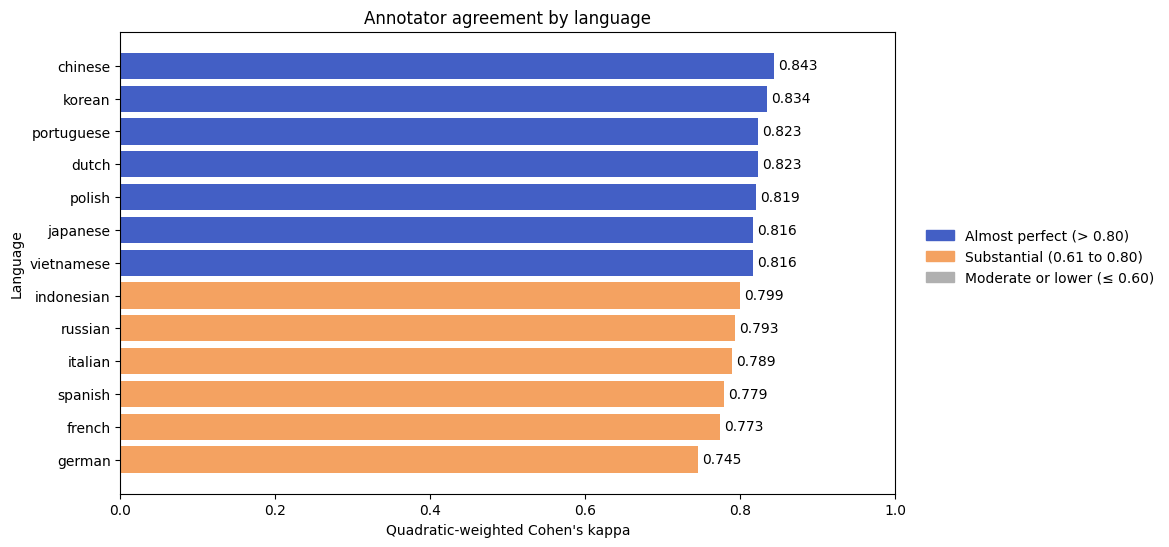

In [120]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

d = cohen_per_language.sort_values("quadratic_kappa").reset_index(drop=True)

def category(k):
    if k > 0.80:
        return "Almost perfect (> 0.80)"
    if k > 0.60:
        return "Substantial (0.61 to 0.80)"
    return "Moderate or lower (≤ 0.60)"

COLORS = {
    "Almost perfect (> 0.80)": "#435FC5",      # blue
    "Substantial (0.61 to 0.80)": "#F4A261",   # orange
    "Moderate or lower (≤ 0.60)": "#B0B0B0",   # gray
}

d["category"] = d["quadratic_kappa"].apply(category)
bar_colors = d["category"].map(COLORS)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(d["language"], d["quadratic_kappa"], color=bar_colors, zorder=2)
ax.bar_label(bars, fmt="%.3f", padding=3)

ax.set_xlim(0, 1)
ax.set_xlabel("Quadratic-weighted Cohen's kappa")
ax.set_ylabel("Language")
ax.set_title("Annotator agreement by language")
ax.legend(handles=[Patch(color=c, label=l) for l, c in COLORS.items()],
          bbox_to_anchor=(1.35, 0.6), frameon=False)

plt.show()